In [3]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "본인이름"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
from preprocessing import *

print(module_test())
print("✅ 준비 완료")

/content/team3-ping-analytics
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 72.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for dbus-python
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (dbus-python)
✅ 모듈 설치 완료
✅ 준비 완료


In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Donghee"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"

!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "polls_question, polls_questionpiece 전처리"
!git push

/content/team3-ping-analytics
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 69.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for dbus-python
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (dbus-python)


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import urllib.request
import seaborn as sns

font_path = "/tmp/Malgun.ttf"
urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf", font_path)

# 최신 matplotlib 버전의 표준 메서드(addfont) 사용
fm.fontManager.addfont(font_path)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

#### 질문 데이터 테이블

In [5]:
# 데이터프레임으로 불러오기
questions = pd.read_csv('/content/drive/MyDrive/00_원본 csv/polls_question.csv')

# 상위 5개 행 확인
print(questions.head())

    id                 question_text           created_at
0   99            가장 신비한 매력이 있는 사람은?  2023-03-31 15:22:53
1  100  "이 사람으로 한 번 살아보고 싶다" 하는 사람은?  2023-03-31 15:22:53
2  101                     미래의 틱톡커는?  2023-03-31 15:22:54
3  102               여기서 제일 특이한 친구는?  2023-03-31 15:22:54
4  103               가장 지켜주고 싶은 사람은?  2023-03-31 15:22:55


### polls_question 전처리

In [6]:
# 필수 컬럼 결측치 제거 및 타입 변환
questions_clean = questions.dropna(subset=['id', 'question_text', 'created_at']).copy()
questions_clean['created_at'] = pd.to_datetime(questions_clean['created_at'])

# 중복 ID 제거 및 created_at 기준 오름차순 정렬
questions_clean = questions_clean.drop_duplicates(subset=['id'])
questions_clean = questions_clean.sort_values(by='created_at', ascending=True)

In [7]:
# 텍스트별 가장 먼저 생성된 대표 ID 추출
text_to_canonical_id = (
    questions_clean.drop_duplicates(subset=['question_text'], keep='first')
    .set_index('question_text')['id']
    .to_dict()
)

# 모든 원본 ID를 대표 ID로 연결하는 맵핑 딕셔너리(id_mapping) 구축
id_mapping = {}
for idx, row in questions_clean.iterrows():
    q_id = row['id']
    q_text = row['question_text']
    if q_text in text_to_canonical_id:
        id_mapping[q_id] = text_to_canonical_id[q_text]

print(f"매핑 딕셔너리 생성 완료: 총 {len(id_mapping)}개의 ID가 매핑되었습니다.")

매핑 딕셔너리 생성 완료: 총 5025개의 ID가 매핑되었습니다.


In [8]:
# 대표 ID 목록 추출
canonical_ids = list(text_to_canonical_id.values())

# 대표 ID에 해당하는 행들만 남기기
questions_clean = questions_clean[questions_clean['id'].isin(canonical_ids)].copy()

print(f"중복 제거 후 남은 최종 질문 데이터 개수: {len(questions_clean)}개")

중복 제거 후 남은 최종 질문 데이터 개수: 3903개


In [9]:
# 전처리가 완료된 questions_clean 테이블을 CSV 파일로 저장
output_path = '/content/drive/MyDrive/00_원본 csv/questions_clean.csv'
questions_clean.to_csv(output_path, index=False, encoding='utf-8-sig')

print(f"파일 저장 완료: {output_path}")

파일 저장 완료: /content/drive/MyDrive/00_원본 csv/questions_clean.csv


#### polls_questionpiece 전처리

#### 질문 조각

In [10]:
# 데이터프레임으로 불러오기
question_piece = pd.read_csv('/content/drive/MyDrive/00_원본 csv/polls_questionpiece.csv')

# 상위 5개 행 확인
print(question_piece.head())

       id  is_voted           created_at  question_id  is_skipped
0  998458         1  2023-04-28 12:27:22          252           0
1  998459         1  2023-04-28 12:27:22          244           0
2  998460         1  2023-04-28 12:27:22          183           0
3  998461         1  2023-04-28 12:27:22          101           0
4  998462         1  2023-04-28 12:27:22          209           0


In [11]:
question_piece

,id,is_voted,created_at,question_id,is_skipped
0,998458,1,2023-04-28 12:27:22,252,0
1,998459,1,2023-04-28 12:27:22,244,0
2,998460,1,2023-04-28 12:27:22,183,0
3,998461,1,2023-04-28 12:27:22,101,0
4,998462,1,2023-04-28 12:27:22,209,0
...,...,...,...,...,...
1265471,208385226,0,2024-05-07 11:32:30,960,0
1265472,208385227,0,2024-05-07 11:32:30,1402,0
1265473,208385228,0,2024-05-07 11:32:30,1676,0
1265474,208385229,0,2024-05-07 11:32:30,3115,0


In [12]:
question_piece.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1265476 entries, 0 to 1265475
Data columns (total 5 columns):
 #   Column       Non-Null Count    Dtype 
---  ------       --------------    ----- 
 0   id           1265476 non-null  int64 
 1   is_voted     1265476 non-null  int64 
 2   created_at   1265476 non-null  object
 3   question_id  1265476 non-null  int64 
 4   is_skipped   1265476 non-null  int64 
dtypes: int64(4), object(1)
memory usage: 48.3+ MB


In [13]:
# 결측치 확인
print("--- polls_questionpiece 결측치 확인 ---")
print(question_piece.isnull().sum())

--- polls_questionpiece 결측치 확인 ---
id             0
is_voted       0
created_at     0
question_id    0
is_skipped     0
dtype: int64


In [14]:
# 필수 컬럼 기준 결측치 제거
essential_cols = ['question_id', 'is_voted', 'is_skipped', 'created_at']
question_piece_clean = question_piece.dropna(subset=essential_cols).copy()

In [15]:
# created_at 컬럼을 datetime 형식으로 변환
question_piece_clean['created_at'] = pd.to_datetime(question_piece_clean['created_at'])

# created_at 최소값 및 최대값 확인
print("\n--- created_at 범위 확인 ---")
print(f"최소값(시작일): {question_piece_clean['created_at'].min()}")
print(f"최대값(종료일): {question_piece_clean['created_at'].max()}")


--- created_at 범위 확인 ---
최소값(시작일): 2023-04-28 12:27:22
최대값(종료일): 2024-05-07 11:32:30


In [16]:
# 타겟 값(is_voted, is_skipped) 타입 정수형 변환 및 범위 확인 (0 또는 1이어야 함)
question_piece_clean['is_voted'] = question_piece_clean['is_voted'].astype(int)
question_piece_clean['is_skipped'] = question_piece_clean['is_skipped'].astype(int)

# 논리적 이상치 확인: 투표와 스킵이 동시에 1이 된 비정상 데이터 체크
invalid_rows = ((question_piece_clean['is_voted'] == 1) & (question_piece_clean['is_skipped'] == 1)).sum()
print(f"\n투표와 스킵이 동시에 체크된 비정상 데이터 개수: {invalid_rows}개")

# 비정상 데이터가 있다면 제거
if invalid_rows > 0:
    question_piece_clean = question_piece_clean[
        ~((question_piece_clean['is_voted'] == 1) & (question_piece_clean['is_skipped'] == 1))
    ]

print(f"polls_questionpiece 전처리 완료 후 최종 데이터 개수: {len(question_piece_clean)}개")


투표와 스킵이 동시에 체크된 비정상 데이터 개수: 1127개
polls_questionpiece 전처리 완료 후 최종 데이터 개수: 1264349개


In [17]:
# is_voted 컬럼의 고유값 확인
print("--- is_voted 컬럼의 고유값 ---")
print(question_piece['is_voted'].value_counts(dropna=False))

# is_skipped 컬럼의 고유값 확인
print("\n--- is_skipped 컬럼의 고유값 ---")
print(question_piece['is_skipped'].value_counts(dropna=False))

# cross_tab(교차표)
# is_voted와 is_skipped의 교차표(Cross-tabulation) 확인
print(pd.crosstab(question_piece['is_voted'], question_piece['is_skipped'], margins=True))

--- is_voted 컬럼의 고유값 ---
is_voted
1    1218687
0      46789
Name: count, dtype: int64

--- is_skipped 컬럼의 고유값 ---
is_skipped
0    1264349
1       1127
Name: count, dtype: int64
is_skipped        0     1      All
is_voted                          
0             46789     0    46789
1           1217560  1127  1218687
All         1264349  1127  1265476


In [18]:
# is_voted와 is_skipped가 동시에 1인 비정상 데이터(로그 오류) 제거
question_piece = question_piece[
    ~((question_piece['is_voted'] == 1) & (question_piece['is_skipped'] == 1))
]

In [19]:
# id_mapping 딕셔너리를 활용해 question_piece의 question_id를 최초 생성된 대표 ID로 직접 치환
question_piece['question_id'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])

# 변환 결과 확인
print(f"question_piece 고유 ID 변환 완료. 총 데이터 행 수: {len(question_piece)}")
print(question_piece.head())

question_piece 고유 ID 변환 완료. 총 데이터 행 수: 1264349
       id  is_voted           created_at  question_id  is_skipped
0  998458         1  2023-04-28 12:27:22          252           0
1  998459         1  2023-04-28 12:27:22          244           0
2  998460         1  2023-04-28 12:27:22          183           0
3  998461         1  2023-04-28 12:27:22          101           0
4  998462         1  2023-04-28 12:27:22          209           0


/tmp/ipykernel_863/2759024848.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  question_piece['question_id'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])


In [20]:
question_piece

,id,is_voted,created_at,question_id,is_skipped
0,998458,1,2023-04-28 12:27:22,252,0
1,998459,1,2023-04-28 12:27:22,244,0
2,998460,1,2023-04-28 12:27:22,183,0
3,998461,1,2023-04-28 12:27:22,101,0
4,998462,1,2023-04-28 12:27:22,209,0
...,...,...,...,...,...
1265471,208385226,0,2024-05-07 11:32:30,960,0
1265472,208385227,0,2024-05-07 11:32:30,1402,0
1265473,208385228,0,2024-05-07 11:32:30,1676,0
1265474,208385229,0,2024-05-07 11:32:30,3115,0


In [21]:
# 전처리가 완료된 question_piece 테이블을 CSV 파일로 저장
output_path = '/content/drive/MyDrive/00_원본 csv/polls_question_piece_cleaned.csv'
question_piece.to_csv(output_path, index=False, encoding='utf-8-sig')

print(f"파일 저장 완료: {output_path}")

파일 저장 완료: /content/drive/MyDrive/00_원본 csv/polls_question_piece_cleaned.csv


#### 맵핑 과정 검증

In [22]:
# question_piece 테이블의 question_id에 앞서 만든 id_mapping 딕셔너리를 적용
# (중복된 질문 ID들을 최초 생성된 대표 ID로 치환하여 데이터 손실 방지)
question_piece['question_id_mapped'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])

# 맵핑된 ID(question_id_mapped)를 기준으로 questions_clean 테이블과 Left Join 결합
df_merged = question_piece.merge(
    questions_clean,
    left_on='question_id_mapped',
    right_on='id',
    how='left',
    suffixes=('_piece', '_question')
)

# 결합 후 데이터프레임 크기 및 결측치 확인
print(f"결합 완료된 df_merged 크기: {df_merged.shape}")
print("--- 결합 후 결측치 확인 ---")
print(df_merged.isnull().sum())

/tmp/ipykernel_863/282077320.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  question_piece['question_id_mapped'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])


결합 완료된 df_merged 크기: (1264349, 9)
--- 결합 후 결측치 확인 ---
id_piece               0
is_voted               0
created_at_piece       0
question_id            0
is_skipped             0
question_id_mapped     0
id_question            0
question_text          0
created_at_question    0
dtype: int64


In [23]:
df_merged

,id_piece,is_voted,created_at_piece,question_id,is_skipped,question_id_mapped,id_question,question_text,created_at_question
0,998458,1,2023-04-28 12:27:22,252,0,252,252,손이 가장 이쁘게 생겼을거 같은 사람은?,2023-04-01 11:09:27
1,998459,1,2023-04-28 12:27:22,244,0,244,244,대학교에서 학생회장할 것 같은 사람은?,2023-04-01 11:09:26
2,998460,1,2023-04-28 12:27:22,183,0,183,183,나의 자존감을 가장 많이 높여줬던 사람은?,2023-04-01 11:09:14
3,998461,1,2023-04-28 12:27:22,101,0,101,101,미래의 틱톡커는?,2023-03-31 15:22:54
4,998462,1,2023-04-28 12:27:22,209,0,209,209,항상 좋은 냄새가 나는 사람은?,2023-04-01 11:09:20
...,...,...,...,...,...,...,...,...,...
1264344,208385226,0,2024-05-07 11:32:30,960,0,960,960,가장 인싸일 것 같은 친구는?,2023-05-15 14:00:19
1264345,208385227,0,2024-05-07 11:32:30,1402,0,1402,1402,가장 리더쉽 있을 것 같은 사람,2023-05-15 14:03:19
1264346,208385228,0,2024-05-07 11:32:30,1676,0,1676,1676,화장 전후 가장 비슷할 것 같은 사람은?,2023-06-02 08:06:24
1264347,208385229,0,2024-05-07 11:32:30,3115,0,3115,3115,가장 박새로이컷이 잘 어울릴 것 같은 사람,2023-06-02 08:07:08


### 1-1 분석

In [24]:
# 1. 질문별 총 노출 횟수 집계
question_exposure = df_merged.groupby('id_question').agg(
    exposure_count=('id_piece', 'count'),
    mean_vote_rate=('is_voted', 'mean')
).reset_index()

# 2. 노출 횟수 분포 요약 통계 확인
print("--- 노출 횟수 요약 통계 ---")
print(question_exposure['exposure_count'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

# 3. 노출 횟수가 1회인 질문 비중 확인
single_exposure_count = (question_exposure['exposure_count'] == 1).sum()
total_questions = len(question_exposure)
print(f"\n노출 횟수가 1회뿐인 질문: {single_exposure_count}개 ({single_exposure_count / total_questions * 100:.2f}%)")

--- 노출 횟수 요약 통계 ---
count     3903.000000
mean       323.942864
std        542.878630
min          1.000000
25%         25.000000
50%         38.000000
75%        379.000000
90%       1462.800000
95%       1672.000000
99%       1893.960000
max      10160.000000
Name: exposure_count, dtype: float64

노출 횟수가 1회뿐인 질문: 2개 (0.05%)


In [25]:
# df_filtered가 정의되지 않은 상태이므로, df_merged를 기준으로 노출 횟수 계산 및 데이터프레임 재생성
exposure_df = df_merged.groupby('id_question').size().reset_index(name='exposure_count')
df_filtered = df_merged.merge(exposure_df, on='id_question', how='left')

# 날짜형 변환 및 경과 일수 계산
df_filtered['created_at_piece'] = pd.to_datetime(df_filtered['created_at_piece'])
df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
df_filtered['question_age_days'] = (df_filtered['created_at_piece'] - df_filtered['created_at_question']).dt.days

# 질문별 노출 횟수 및 최초/최종 노출 시점, 투표 여부 집계
question_summary = df_filtered.groupby('id_question').agg(
    exposure_count=('id_piece', 'count'),
    created_at_question=('created_at_question', 'first'),
    first_exposure=('created_at_piece', 'min'),
    last_exposure=('created_at_piece', 'max'),
    vote_sum=('is_voted', 'sum')
).reset_index()

# 질문 생존 일수 계산
question_summary['question_lifespan_days'] = (question_summary['last_exposure'] - question_summary['created_at_question']).dt.days

# 노출 수가 5회 이하인 '저노출 질문' 필터링
low_exposure_questions = question_summary[question_summary['exposure_count'] <= 10]

print(f"전체 질문 수: {len(question_summary):,d}개")
print(f"노출 수 5회 이하인 저노출 질문 수: {len(low_exposure_questions):,d}개 ({len(low_exposure_questions)/len(question_summary)*100:.1f}%)")

print("\n--- 저노출 질문의 생존 일수 및 투표 현황 요약 ---")
print(low_exposure_questions[['exposure_count', 'question_lifespan_days', 'vote_sum']].describe())

전체 질문 수: 3,903개
노출 수 5회 이하인 저노출 질문 수: 39개 (1.0%)

--- 저노출 질문의 생존 일수 및 투표 현황 요약 ---
       exposure_count  question_lifespan_days   vote_sum
count       39.000000               39.000000  39.000000
mean         8.538462               95.179487   5.923077
std          2.382460               76.781259   2.464320
min          1.000000               11.000000   0.000000
25%          8.000000               37.000000   5.000000
50%          9.000000               74.000000   6.000000
75%         10.000000              118.500000   8.000000
max         10.000000              321.000000  10.000000


In [26]:
# 1. 노출 수가 5회 이하인 저노출 질문 ID 추출
low_exposure_ids = question_summary[question_summary['exposure_count'] <= 10]['id_question']

# 2. 해당 저노출 질문들의 전체 노출 로그 데이터 필터링
df_low_exposure = df_filtered[df_filtered['id_question'].isin(low_exposure_ids)].copy()

# 3. 질문 생성일 기준으로 각 노출일이 며칠 만에 이루어졌는지 확인하기 위한 컬럼 선택
low_exposure_details = df_low_exposure[[
    'id_question',
    'question_text',
    'created_at_question',
    'created_at_piece',
    'question_age_days',
    'exposure_count'
]].sort_values(by=['id_question', 'created_at_piece'])

# 상위 20개 결과 출력
print(low_exposure_details.head(40))

         id_question         question_text created_at_question  \
1224166         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1225047         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1226521         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1228304         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1238627         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1239762         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1249069         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1250130         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1263084         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1219422         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1225599         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1230353         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1233759         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1235857         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1246151   

In [27]:
# 각 질문(id_question)별로 question_age_days가 가장 큰(가장 오래된 노출) 행의 인덱스를 추출
idx_max_age = df_filtered.groupby('id_question')['question_age_days'].idxmax()

# 해당 행들만 필터링하여 필요한 컬럼만 보기 쉽게 구성
oldest_exposure_per_question = df_filtered.loc[idx_max_age, [
    'id_question',
    'question_text',
    'created_at_question',
    'created_at_piece',
    'question_age_days',
    'exposure_count'
]].reset_index(drop=True)

# 경과 일수가 긴 순서대로 정렬하여 상위 20개 확인
oldest_exposure_per_question = oldest_exposure_per_question.sort_values(by='question_age_days', ascending=False)

print(oldest_exposure_per_question.tail(20))

      id_question                  question_text created_at_question  \
1462         1593        손이 닿았을 때 가장 설렐것 같은 사람은? 2023-05-15 14:04:36   
1456         1586             사귀면 애교가 많을 것 같은 사람 2023-05-15 14:04:33   
1994         2167               웹툰에 나올 것 같은 사람은? 2023-06-02 08:06:39   
2708         2927       기념일 엄청 꼼꼼하게 챙길 것 같은 사람은? 2023-06-02 08:07:02   
1814         1974  좋아하는 사람이 있는데 숨기고 있을 것 같은 사람은? 2023-06-02 08:06:33   
2024         2201           옷장이 제일 깔끔할 것 같은 사람은? 2023-06-02 08:06:40   
1669         1822          큰 돈을 바로 빌려줄 것 같은 친구는? 2023-06-02 08:06:28   
2717         2936                  군인이 어울리는 친구는? 2023-06-02 08:07:03   
2647         2859            나중에 외제차 탈 것 같은 사람은? 2023-06-02 08:07:00   
3132         3375          학원을 제일 많이 다닐것 같은 친구는? 2023-06-06 06:10:07   
1543         1685          혼자 다니면 길 잃어버릴 것 같은 친구 2023-06-02 08:06:24   
2365         2559         발에서 블루베리 향 날 것 같은 사람은? 2023-06-02 08:06:51   
3497         3746         시험지 찍으면 다 틀릴 것 같은 친구는? 2023-06-06 06:1

In [28]:
# 노출 횟수가 정확히 1회인 데이터 필터링
single_exposure_df = df_filtered[df_filtered['exposure_count'] == 20].copy()

print(f"노출 횟수가 1회인 전체 데이터 행 수: {len(single_exposure_df):,d}개")

# 필요한 컬럼만 추출하여 상위 20개 확인
print("\n--- 노출 횟수 1회 데이터 샘플 ---")
print(single_exposure_df[[
    'id_question',
    'question_text',
    'created_at_question',
    'created_at_piece',
    'question_age_days',
    'exposure_count'
]].head(20))

노출 횟수가 1회인 전체 데이터 행 수: 1,640개

--- 노출 횟수 1회 데이터 샘플 ---
         id_question        question_text created_at_question  \
1189417         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1189499         2415    성우하면 좋을 것 같은 사람은? 2023-06-02 08:06:46   
1189541         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1192289         2415    성우하면 좋을 것 같은 사람은? 2023-06-02 08:06:46   
1193484         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1193642         2415    성우하면 좋을 것 같은 사람은? 2023-06-02 08:06:46   
1194370         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1195745         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1198583         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1200743         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1203964         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1204579         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1205146         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1205336         1783  포근해서 계속 안기고 싶

In [29]:
# 질문 생성일과 노출(응답)일의 차이(question_age_days)가 0인 데이터 필터링
zero_age_df = df_filtered[df_filtered['question_age_days'] == 0].copy()

print(f"생성 당일 노출된 데이터 행 수: {len(zero_age_df):,d}개 (전체의 {len(zero_age_df)/len(df_filtered)*100:.2f}%)")

# 주요 컬럼 추출하여 상위 20개 샘플 확인
print("\n--- 생성 당일 노출 데이터 샘플 ---")
print(zero_age_df[[
    'id_question',
    'question_text',
    'created_at_question',
    'created_at_piece',
    'question_age_days',
    'exposure_count'
]].head(20))

생성 당일 노출된 데이터 행 수: 66,472개 (전체의 5.26%)

--- 생성 당일 노출 데이터 샘플 ---
       id_question                 question_text created_at_question  \
48350          373                        영어 ACE 2023-05-02 05:32:43   
48351          398                등빨이 가장 좋은 사람은? 2023-05-02 05:32:50   
48369          387             주짓수 같이 하고 싶은 사람은? 2023-05-02 05:32:47   
48370          427  요즘 유행하는 밈을 다 알고 있을 것 같은 사람은? 2023-05-02 05:32:56   
48371          343               연락을 잘 받아주는 친구는? 2023-05-02 05:32:36   
48373          410       발냄새가 호두과자 냄새일 것 같은 사람은? 2023-05-02 05:32:52   
48375          383             워터파크 같이 가고싶은 사람은? 2023-05-02 05:32:46   
48376          491       조언이 필요할 때 가장 먼저 찾는 친구는? 2023-05-02 05:33:13   
48377          379           롯데월드 둘이서 가고 싶은 사람은? 2023-05-02 05:32:45   
48381          425              닮은꼴 연예인이 있는 사람은? 2023-05-02 05:32:56   
48382          449        ISFJ에 가장 가까울 것 같은 사람은? 2023-05-02 05:33:02   
48383          524               웃는 모습이 호감인 친구는? 2023-05-02 05:33:22   


In [30]:
# 1. 생성일이 2023년 6월 6일인 데이터 필터링
df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
target_date = pd.to_datetime('2023-06-06').date()

date_target_df = df_filtered[df_filtered['created_at_question'].dt.date == target_date].copy()

# 2. 질문별 고유 정보 및 노출 횟수 추출 (중복 행 제거)
questions_by_date = date_target_df[['id_question', 'question_text', 'exposure_count', 'created_at_question']].drop_duplicates()

# 3. 노출 횟수가 높은 순서(내림차순)로 정렬
questions_sorted = questions_by_date.sort_values(by='exposure_count', ascending=False).reset_index(drop=True)

print(f"2023년 6월 6일에 생성된 총 질문 수: {len(questions_sorted):,d}개")
print("\n--- 노출 횟수 상위 질문 목록 ---")
print(questions_sorted.head(2000))

2023년 6월 6일에 생성된 총 질문 수: 972개

--- 노출 횟수 상위 질문 목록 ---
     id_question                         question_text  exposure_count  \
0           3565                             신비로운 친구는?              35   
1           4043             사투리를 가장 맛깔나게 살릴 것 같은 사람은?              34   
2           3612                          은근 재능충인 사람은?              34   
3           4013                   혼자서도 잘해먹고 살것 같은사람은?              32   
4           3664                    벙거지가 잘 어울릴 것 같은 사람              32   
..           ...                                   ...             ...   
967         3860                   한번쯤 목마를 태워주고 싶은사람은?               7   
968         4412  할머니,  할아버지가 돼도 이 친구만큼은 연락하고 지낼 것 같아!               5   
969         4280          너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!                2   
970         4313                  사달라는거 다 사줄 것 같은 사람은?               1   
971         4970                   개학 하자마자 인사 될것 같은 사람               1   

    created_at_question  
0   2023-06-06 06:10:10  
1   2

- 질문의 마지막 생성일인 2023-06-06일에 가까울 수록 질문의 노출 빈도가 적음

In [31]:
# 1. 생성일 컬럼을 datetime으로 변환 후 날짜만 추출
df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
df_filtered['question_date'] = df_filtered['created_at_question'].dt.date

# 2. 존재하는 모든 질문 생성일을 내림차순(최신순)으로 정렬하여 고유값 추출
unique_dates = sorted(df_filtered['question_date'].unique(), reverse=True)

# 3. 가장 마지막 날짜(2023-06-06)의 바로 직전 날짜(인덱스 1) 자동 탐색
if len(unique_dates) > 1:
    prev_target_date = unique_dates[1]
    print(f"탐색된 직전 질문 생성일: {prev_target_date}")

    # 4. 직전 생성일에 만들어진 데이터 필터링
    date_target_df = df_filtered[df_filtered['question_date'] == prev_target_date].copy()

    # 5. 질문별 고유 정보 및 노출 횟수 추출 (중복 행 제거)
    questions_by_date = date_target_df[['id_question', 'question_text', 'exposure_count', 'created_at_question']].drop_duplicates()

    # 6. 노출 횟수가 높은 순서(내림차순)로 정렬
    questions_sorted = questions_by_date.sort_values(by='exposure_count', ascending=False).reset_index(drop=True)

    print(f"{prev_target_date}에 생성된 총 질문 수: {len(questions_sorted):,d}개")
    print("\n--- 직전 생성일 노출 횟수 상위 질문 목록 ---")
    print(questions_sorted.head(20))
else:
    print("비교할 수 있는 이전 생성일이 존재하지 않습니다.")

탐색된 직전 질문 생성일: 2023-06-02
2023-06-02에 생성된 총 질문 수: 1,418개

--- 직전 생성일 노출 횟수 상위 질문 목록 ---
    id_question                question_text  exposure_count  \
0          2428               선물을 주고 싶은 사람은?              83   
1          2220              연예인의 기질이 보이는 친구              82   
2          1772            플래너 잘 쓸 것 같은 사람은?              79   
3          2007            제일 마음씨 착할 것 같은 친구              75   
4          1670             회사 비서에 잘 어울리는 사람              75   
5          2801       내가 전화하면 바로 달려올 것 같은 친구              74   
6          2052             잠버릇이 특이할 것 같은 친구              73   
7          3084            가장 열심히 사는 것 같은 사람              68   
8          2128                   이 학교의 퀸카는?              64   
9          2720              돈 관리 잘할 것 같은 친구              64   
10         2775       노래방에서 같이 춤 출 수 있는 친구는?              63   
11         2449            새해 첫날에 보고 싶은 친구는?              62   
12         1929        집안일을 가장 잘 할 것 같은 사람은?              61   
13         2868 

In [32]:
# 1. 생성일 컬럼을 datetime으로 변환 후 날짜 추출
df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
df_filtered['question_date'] = df_filtered['created_at_question'].dt.date

# 2. 존재하는 모든 질문 생성일을 내림차순(최신순)으로 정렬
unique_dates = sorted(df_filtered['question_date'].unique(), reverse=True)

# 3. 모든 생성일에 대해 반복문 수행 (전체 날짜를 보려면 슬라이싱을 제거하거나 조절하세요)
for target_date in unique_dates:  # 전체 날짜를 순회하려면 unique_dates 그대로 사용
    print(f"\n==================== [생성일: {target_date}] ====================")

    # 해당 날짜에 생성된 데이터 필터링
    date_target_df = df_filtered[df_filtered['question_date'] == target_date].copy()

    # 질문별 고유 정보 및 노출 횟수 추출 (중복 제거)
    questions_by_date = date_target_df[['id_question', 'question_text', 'exposure_count', 'created_at_question']].drop_duplicates()

    # 노출 횟수가 높은 순서(내림차순)로 정렬
    questions_sorted = questions_by_date.sort_values(by='exposure_count', ascending=False).reset_index(drop=True)

    print(f"총 질문 수: {len(questions_sorted):,d}개")
    print("--- 노출 횟수 상위 5개 질문 ---")
    print(questions_sorted.head(3))
    print('----------------------------------------------------------------------------------------------------')
    print("--- 노출 횟수 하위 5개 질문 ---")
    print(questions_sorted.tail(3))


==================== [생성일: 2023-06-06] ====================
총 질문 수: 972개
--- 노출 횟수 상위 5개 질문 ---
   id_question              question_text  exposure_count created_at_question
0         3565                  신비로운 친구는?              35 2023-06-06 06:10:10
1         4043  사투리를 가장 맛깔나게 살릴 것 같은 사람은?              34 2023-06-06 06:10:16
2         3612               은근 재능충인 사람은?              34 2023-06-06 06:10:10
----------------------------------------------------------------------------------------------------
--- 노출 횟수 하위 5개 질문 ---
     id_question                 question_text  exposure_count  \
969         4280  너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!                2   
970         4313          사달라는거 다 사줄 것 같은 사람은?               1   
971         4970           개학 하자마자 인사 될것 같은 사람               1   

    created_at_question  
969 2023-06-06 06:15:40  
970 2023-06-06 06:15:41  
971 2023-06-06 06:15:50  

==================== [생성일: 2023-06-02] ====================
총 질문 수: 1,418개
--- 노출 횟수 상위 5개 질문 ---

--- 생애 주기별 투표율 감쇠 집계 결과 ---
  age_group  total_exposure  vote_count  vote_rate
0     1일 이내          137653      132803   0.964766
1      2~3일          129924      125780   0.968104
2      4~7일          197520      190025   0.962054
3     8~14일          275288      265191   0.963322
4    15~30일          149141      141954   0.951811
5    31~60일          365444      356435   0.975348
6    60일 이상            9379        5372   0.572769


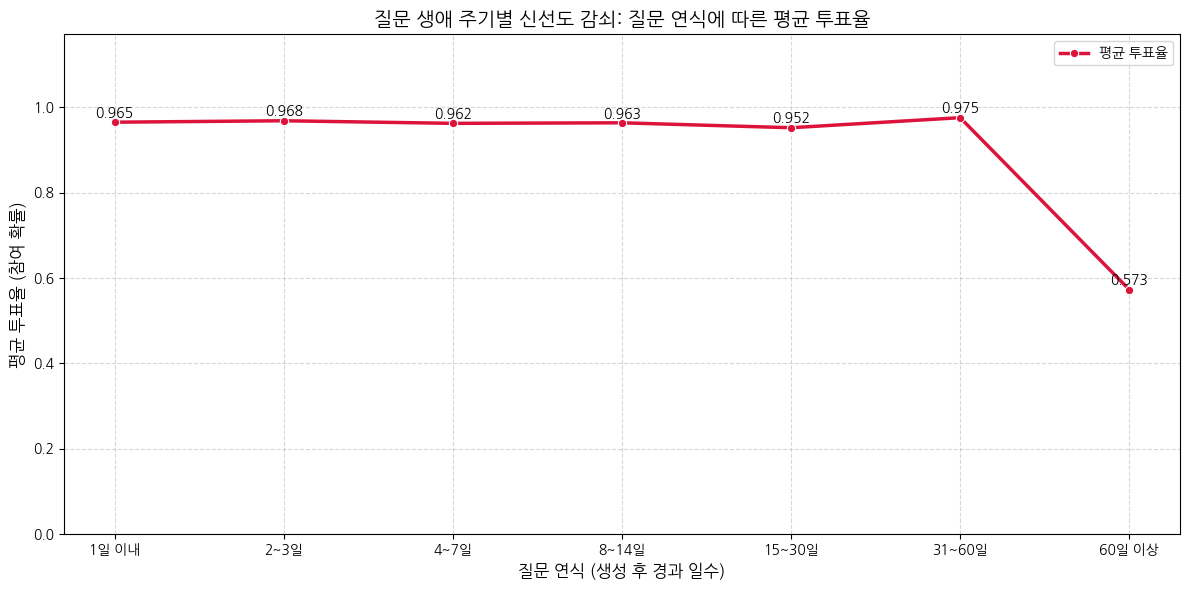

In [33]:
# 1. 날짜형 변환 및 경과 일수(Question Age) 계산
# (이미 수행했다면 생략 가능합니다)
df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
df_filtered['created_at_piece'] = pd.to_datetime(df_filtered['created_at_piece'])
df_filtered['question_age_days'] = (df_filtered['created_at_piece'] - df_filtered['created_at_question']).dt.days

# 음수 값(데이터 오차 등으로 노출일이 생성일보다 앞선 경우) 예외 처리
df_filtered = df_filtered[df_filtered['question_age_days'] >= 0].copy()

# 2. 질문의 생애 주기 구간(Bins) 설정
# 질문이 태어난 직후의 변화를 세밀하게 보기 위해 초기 구간을 촘촘하게 설정합니다.
bins = [-1, 1, 3, 7, 14, 30, 60, float('inf')]
labels = ['1일 이내', '2~3일', '4~7일', '8~14일', '15~30일', '31~60일', '60일 이상']

df_filtered['age_group'] = pd.cut(df_filtered['question_age_days'], bins=bins, labels=labels)

# 3. 생애 주기 구간별 총 노출 수 및 평균 투표율(Vote Rate) 집계
freshness_decay_df = df_filtered.groupby('age_group', observed=False).agg(
    total_exposure=('id_piece', 'count'),       # 구간별 총 노출 횟수
    vote_count=('is_voted', 'sum'),            # 구간별 총 투표 수
    vote_rate=('is_voted', 'mean')             # 평균 투표율 (참여율)
).reset_index()

print("--- 생애 주기별 투표율 감쇠 집계 결과 ---")
print(freshness_decay_df)

# 4. 신선도 감쇠 곡선(Freshness Decay Curve) 시각화
plt.figure(figsize=(12, 6))

# 투표율 선 그래프 그리기
ax1 = sns.lineplot(
    data=freshness_decay_df,
    x='age_group',
    y='vote_rate',
    marker='o',
    color='crimson',
    linewidth=2.5,
    label='평균 투표율'
)

plt.title('질문 생애 주기별 신선도 감쇠: 질문 연식에 따른 평균 투표율', fontsize=14, fontweight='bold')
plt.xlabel('질문 연식 (생성 후 경과 일수)', fontsize=12)
plt.ylabel('평균 투표율 (참여 확률)', fontsize=12)
plt.ylim(0, max(freshness_decay_df['vote_rate']) * 1.2)
plt.grid(True, linestyle='--', alpha=0.5)

# 값 데이터 라벨 추가
for i, row in freshness_decay_df.iterrows():
    ax1.text(i, row['vote_rate'] + 0.01, f"{row['vote_rate']:.3f}",
             color='black', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

--- 60일 이후 세분화된 생애 주기별 투표율 감쇠 결과 ---
  age_group_detailed  total_exposure  vote_count  vote_rate
0              1일 이내          137653      132803   0.964766
1               2~3일          129924      125780   0.968104
2               4~7일          197520      190025   0.962054
3              8~14일          275288      265191   0.963322
4             15~30일          149141      141954   0.951811
5             31~60일          365444      356435   0.975348
6             61~90일            4628        3283   0.709378
7            91~120일            1910         855   0.447644
8            120일 이상            2841        1234   0.434354


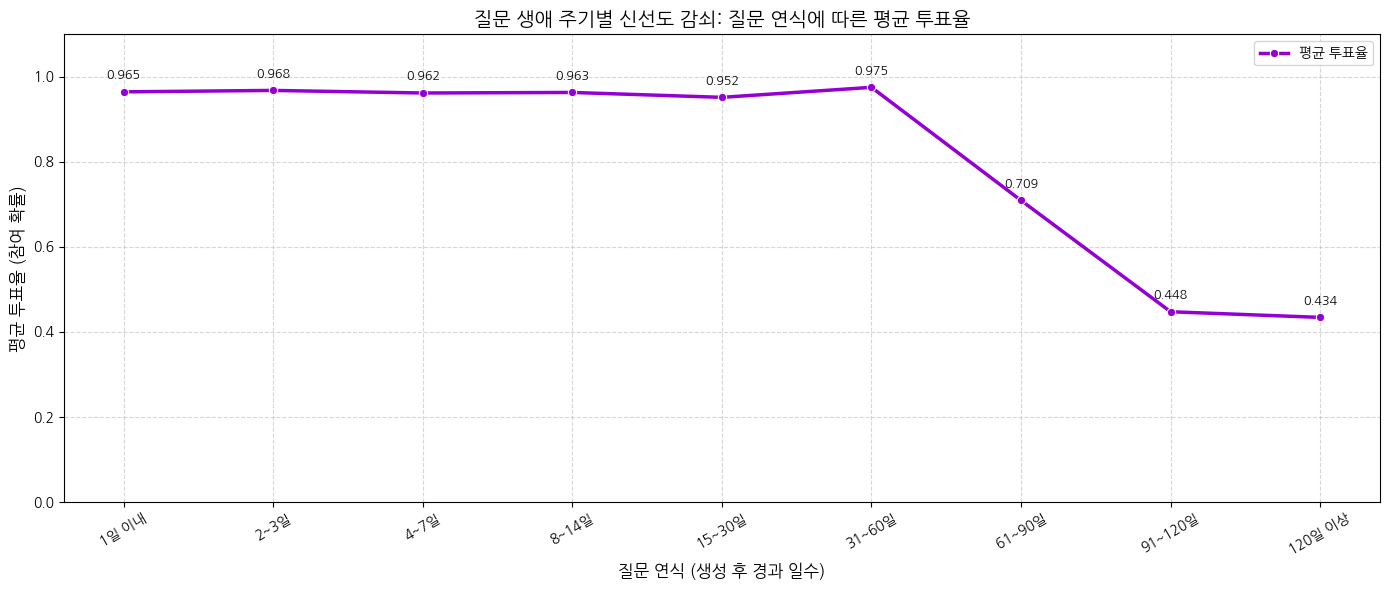

In [34]:
# 1. 60일 이후 구간을 더 세분화한 Bins 설정 (예: 60~90일, 90~120일, 120일 이상)
bins_detailed = [-1, 1, 3, 7, 14, 30, 60, 90, 120, float('inf')]
labels_detailed = ['1일 이내', '2~3일', '4~7일', '8~14일', '15~30일', '31~60일', '61~90일', '91~120일', '120일 이상']

df_filtered['age_group_detailed'] = pd.cut(df_filtered['question_age_days'], bins=bins_detailed, labels=labels_detailed)

# 2. 세분화된 구간별 집계
freshness_decay_detailed = df_filtered.groupby('age_group_detailed', observed=False).agg(
    total_exposure=('id_piece', 'count'),
    vote_count=('is_voted', 'sum'),
    vote_rate=('is_voted', 'mean')
).reset_index()

print("--- 60일 이후 세분화된 생애 주기별 투표율 감쇠 결과 ---")
print(freshness_decay_detailed)

# 3. 세분화된 신선도 감쇠 곡선 시각화
plt.figure(figsize=(14, 6))

ax2 = sns.lineplot(
    data=freshness_decay_detailed,
    x='age_group_detailed',
    y='vote_rate',
    marker='o',
    color='darkviolet',
    linewidth=2.5,
    label='평균 투표율'
)

plt.title('질문 생애 주기별 신선도 감쇠: 질문 연식에 따른 평균 투표율', fontsize=14, fontweight='bold')
plt.xlabel('질문 연식 (생성 후 경과 일수)', fontsize=12)
plt.ylabel('평균 투표율 (참여 확률)', fontsize=12)
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.5)

# 값 데이터 라벨 추가
for i, row in freshness_decay_detailed.iterrows():
    ax2.text(i, row['vote_rate'] + 0.03, f"{row['vote_rate']:.3f}",
             color='black', ha='center', fontsize=9)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### 일별

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 날짜형 변환 및 질문 경과 일수(Age) 계산
df_merged['created_at_piece'] = pd.to_datetime(df_merged['created_at_piece'])
df_merged['created_at_question'] = pd.to_datetime(df_merged['created_at_question'])
df_merged['question_age_days'] = (df_merged['created_at_piece'] - df_merged['created_at_question']).dt.days

# 2. 음수 오차 데이터 필터링 (시스템 시계 오차 등으로 로그가 질문 생성보다 미세하게 빠른 경우)
df_analysis = df_merged[df_merged['question_age_days'] >= 0].copy()

# 3. 경과 일수별 전체 노출 수와 평균 투표율 집계
age_trend = df_analysis.groupby('question_age_days')['is_voted'].agg(
    total_exposure='count',
    vote_rate='mean'
).reset_index()

print(age_trend.head(15))

    question_age_days  total_exposure  vote_rate
0                   0           66472   0.960946
1                   1           71181   0.968334
2                   2           61341   0.969058
3                   3           68583   0.967251
4                   4           55556   0.962236
5                   5           55514   0.963595
6                   6           46029   0.958961
7                   7           40421   0.963212
8                   8           40255   0.964501
9                   9           38256   0.968632
10                 10           41943   0.970531
11                 11           50668   0.970514
12                 12           46982   0.964603
13                 13           35339   0.952376
14                 14           21845   0.936278


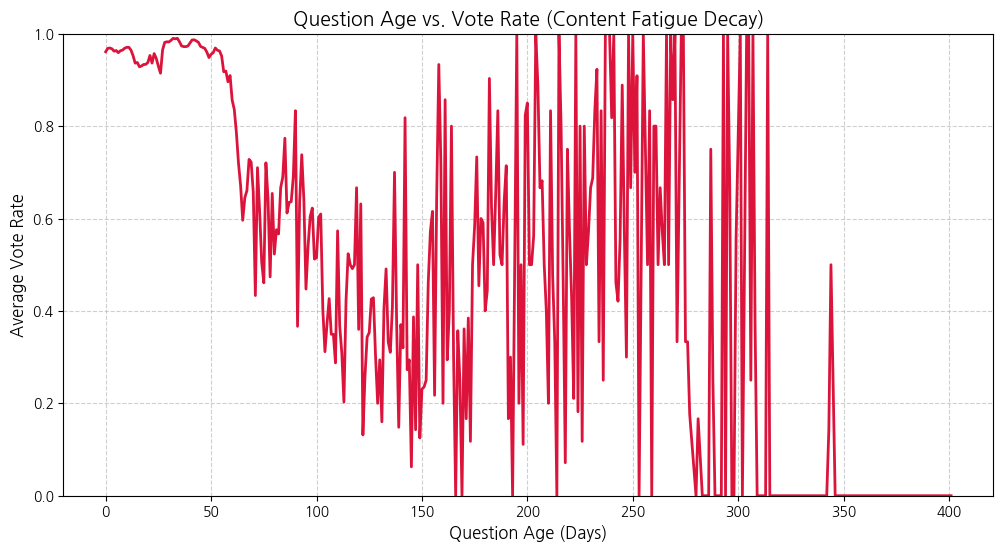

In [36]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=age_trend, x='question_age_days', y='vote_rate', color='crimson', linewidth=2)
plt.title('Question Age vs. Vote Rate (Content Fatigue Decay)', fontsize=14)
plt.xlabel('Question Age (Days)', fontsize=12)
plt.ylabel('Average Vote Rate', fontsize=12)
plt.ylim(0, 1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [37]:
# 1. 경과 일수 구간(Bins) 설정 및 라벨링
bins = [-1, 7, 30, 90, 180, 365, float('inf')]
labels = ['0~7일 (신규/최상)', '8~30일 (안정기)', '31~90일 (노후화 초기)', '91~180일 (노후화 심화)', '181~365일 (방치)', '1년 이상 (고착화)']

df_analysis['age_group'] = pd.cut(df_analysis['question_age_days'], bins=bins, labels=labels)

# 2. 구간별 총 노출 수, 평균 투표율 집계
freshness_trend = df_analysis.groupby('age_group', observed=False)['is_voted'].agg(
    total_exposure='count',
    vote_rate='mean'
).reset_index()

# 전체 노출 중 해당 구간이 차지하는 비중(%) 계산
total_exposures_sum = freshness_trend['total_exposure'].sum()
freshness_trend['exposure_share'] = (freshness_trend['total_exposure'] / total_exposures_sum) * 100

print(freshness_trend)

          age_group  total_exposure  vote_rate  exposure_share
0      0~7일 (신규/최상)          465097   0.964547       36.785492
1       8~30일 (안정기)          424429   0.959277       33.568975
2   31~90일 (노후화 초기)          370072   0.972022       29.269766
3  91~180일 (노후화 심화)            3422   0.414670        0.270653
4     181~365일 (방치)            1320   0.507576        0.104402
5       1년 이상 (고착화)               9   0.000000        0.000712


/tmp/ipykernel_863/2146579494.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=freshness_trend, x='age_group', y='vote_rate', ax=ax1, palette='Reds_r', alpha=0.8)


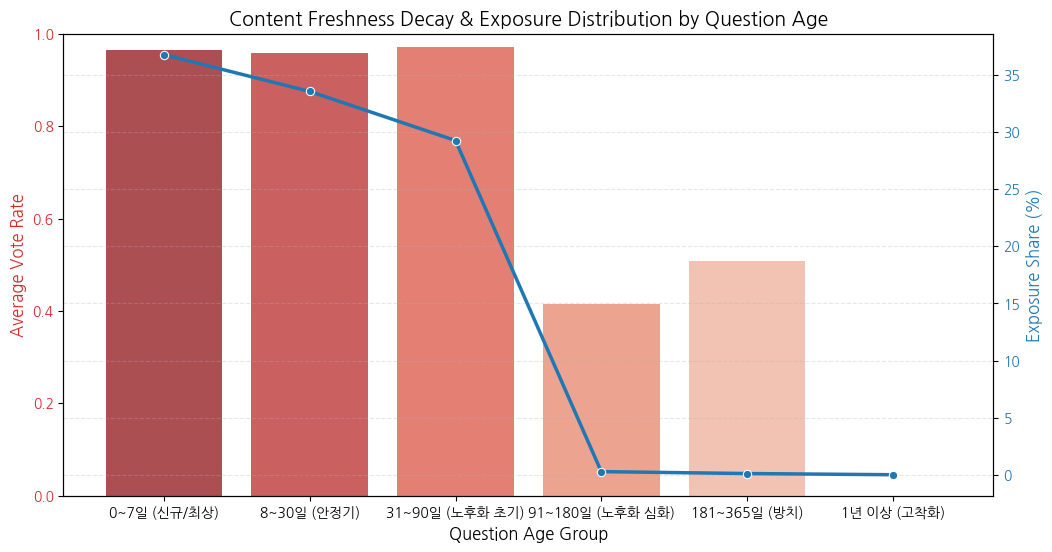

In [38]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# 투표율 추세 (막대 그래프)
color = 'tab:red'
ax1.set_xlabel('Question Age Group', fontsize=12)
ax1.set_ylabel('Average Vote Rate', color=color, fontsize=12)
sns.barplot(data=freshness_trend, x='age_group', y='vote_rate', ax=ax1, palette='Reds_r', alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

# 노출 비중 (선 그래프)
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Exposure Share (%)', color=color, fontsize=12)
sns.lineplot(data=freshness_trend, x='age_group', y='exposure_share', ax=ax2, color=color, marker='o', linewidth=2.5)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Content Freshness Decay & Exposure Distribution by Question Age', fontsize=14)
plt.xticks(rotation=15)
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()